In [1]:
from itscalledsoccer.client import AmericanSoccerAnalysis
from plotnine import *
from colour import Color
import numpy as np
import pandas as pd

from sophso import (
    decorate_team_ids,
    nwsl_primary_colors,
    geom_image,
    decorate_player_ids,
)

asa_client = AmericanSoccerAnalysis()

In [2]:
games_df = decorate_team_ids(asa_client.get_games(leagues="nwsl", seasons="2025"))
games_df.T

,0,1,2,3,4,5,6,10,12,11,...,180,181,182,183,184,185,186,187,188,189
game_id,wvq9koO3MW,vzqoYEy7Ma,gOMnGEN65w,0Oq6o6WrQ6,NWMWk0beMl,7VqGX8zAQv,0x5gxE17q7,NWMWp4875l,eVq3bDp65W,Oa5wj2OjM1,...,kRQajgrmMK,xW5pb8nGQg,KPqjjVEnq6,aDQ0b6oB5E,9vQ2bnVYQK,NPqxj8dGM9,odMXpkWrMY,9YqdjO2jMv,KXMeZn0X56,aDQ0b6JW5E
date_time_utc,2025-11-23 01:00:00 UTC,2025-11-16 20:00:00 UTC,2025-11-15 17:00:00 UTC,2025-11-09 20:00:00 UTC,2025-11-09 17:30:00 UTC,2025-11-08 17:00:00 UTC,2025-11-08 01:00:00 UTC,2025-11-02 22:15:00 UTC,2025-11-02 22:15:00 UTC,2025-11-02 22:15:00 UTC,...,2025-03-22 23:00:00 UTC,2025-03-22 02:00:00 UTC,2025-03-16 22:50:00 UTC,2025-03-16 02:00:00 UTC,2025-03-16 00:00:00 UTC,2025-03-15 23:30:00 UTC,2025-03-15 16:45:00 UTC,2025-03-15 00:00:00 UTC,2025-03-15 00:00:00 UTC,2025-03-08 01:00:00 UTC
home_score,0,0,2,1,1,1,2,1,1,2,...,1,1,1,1,1,1,3,1,6,1
away_score,1,1,0,0,2,1,0,1,0,1,...,2,1,1,1,1,1,1,2,0,1
home_team_id,aDQ0lzvQEv,XVqKeVKM01,aDQ0lzvQEv,Pk5LeeNqOW,4wM4rZdqjB,aDQ0lzvQEv,XVqKeVKM01,XVqKeVKM01,eV5DR6YQKn,KPqjw8PQ6v,...,zeQZeazqKw,Pk5LeeNqOW,kRQa8JOqKZ,7vQ7BBzqD1,eV5DR6YQKn,eV5D2w9QKn,4wM4rZdqjB,4JMAk47qKg,XVqKeVKM01,XVqKeVKM01
away_team_id,raMyrr25d2,raMyrr25d2,Pk5LeeNqOW,7VqG1lYMvW,raMyrr25d2,eV5DR6YQKn,7vQ7BBzqD1,7vQ7BBzqD1,315VnJ759x,kRQa8JOqKZ,...,7vQ7BBzqD1,kRQa8JOqKZ,7VqG1lYMvW,raMyrr25d2,zeQZeazqKw,315VnJ759x,Pk5LeeNqOW,aDQ0lzvQEv,KPqjw8PQ6v,aDQ0lzvQEv
referee_id,Xj5YWgaQbd,vzqokJLqap,KAqBE1B5bg,315VVZY59x,NWMWR3DQlz,EGMPOOyQaY,2vQ1VL4MrA,KAqBE1B5bg,e7MzyK9Qr0,KAqBp74Mbg,...,eVq3J465WO,a35rgwBqL6,0Oq6AZ756D,a35r3kGqL6,e7Mz8Eeqr0,KPqj32nQ6v,ljqEmaAqx0,gpMO6A2Qzy,e7MzyK9Qr0,a35r3kGqL6
stadium_id,Vj58W84M8n,vzqoJrj5ap,xW5pwORMg1,p6qbX06M0G,xW5p3L0Mg1,xW5pwORMg1,vzqoJrj5ap,vzqoJrj5ap,BLMvra8Mxe,9YqdkYR5vJ,...,gpMOrLOQzy,p6qbX06M0G,7vQ7xbOMD1,9Yqda07QvJ,BLMvra8Mxe,e7MzlRjqr0,xW5p3L0Mg1,0x5g6ojM7O,vzqoJrj5ap,vzqoJrj5ap
home_manager_id,NPqxDAgq9d,jYQJJ1VQGR,NPqxDAgq9d,XVqKEk0M01,vzqo3mNqap,NPqxDAgq9d,jYQJJ1VQGR,jYQJJ1VQGR,kRQa4GoqKZ,eVq3Y6XMWO,...,p6qbJw3q0G,XVqKEk0M01,9YqdZ39MvJ,OlMlY7P5Lz,kRQa4GoqKZ,9vQ2YGaqK6,vzqo3mNqap,KPqjdAEM6v,jYQJJ1VQGR,jYQJJ1VQGR
away_manager_id,9vQ2r1LQK6,9vQ2r1LQK6,XVqKEk0M01,zeQZzPgQKw,9vQ2r1LQK6,kRQa4GoqKZ,OlMlY7P5Lz,OlMlY7P5Lz,NPqxLwgq9d,NWMWPDe5lz,...,OlMlY7P5Lz,9YqdZ39MvJ,zeQZzPgQKw,9vQ2r1LQK6,p6qbJw3q0G,NPqxLwgq9d,XVqKEk0M01,9YqdzzjMvJ,2lqRGexQr0,9YqdzzjMvJ


In [3]:
pd.to_datetime(games_df.date_time_utc).dt.strftime("%Y-%m-%d")

0      2025-11-23
1      2025-11-16
2      2025-11-15
3      2025-11-09
4      2025-11-09
          ...    
185    2025-03-15
186    2025-03-15
187    2025-03-15
188    2025-03-15
189    2025-03-08
Name: date_time_utc, Length: 190, dtype: object

In [4]:
(
    games_df.home_team
    + " vs "
    + games_df.away_team
    + ": "
    + pd.to_datetime(games_df.date_time_utc).dt.strftime("%Y-%m-%d")
)

0      WAS vs NJY: 2025-11-23
1      ORL vs NJY: 2025-11-16
2      WAS vs POR: 2025-11-15
3       POR vs SD: 2025-11-09
4       KC vs NJY: 2025-11-09
                ...          
185    UTA vs BAY: 2025-03-15
186     KC vs POR: 2025-03-15
187    HOU vs WAS: 2025-03-15
188    ORL vs CHI: 2025-03-15
189    ORL vs WAS: 2025-03-08
Length: 190, dtype: object

In [5]:
def decorate_game_ids(df):
    game_ids = set(df.game_id.to_list())

    games_df = decorate_team_ids(asa_client.get_games(game_ids=list(game_ids)))
    games_df["game_desc"] = (
        games_df.home_team
        + " vs "
        + games_df.away_team
        + ": "
        + pd.to_datetime(games_df.date_time_utc).dt.strftime("%Y-%m-%d")
    )

    team_map = dict(zip(games_df.game_id, games_df.game_desc))

    df["game_desc"] = df["game_id"].map(team_map)

    return df

In [6]:
decorate_team_ids(
    decorate_game_ids(
        decorate_player_ids(
            asa_client.get_goalkeeper_xgoals(
                leagues="nwsl", season=["2025"], split_by_games=True
            )
        )
    )
).sort_values("goals_minus_xgoals_gk", ascending=True).head(10)

,player_id,game_id,team_id,minutes_played,shots_faced,goals_conceded,saves,share_headed_shots,xgoals_gk_faced,goals_minus_xgoals_gk,goals_divided_by_xgoals_gk,player,player_headshot,game_desc,team,team_logo
197,NWMWo0RzMl,KXMeZ6Or56,eV5DR6YQKn,107,5,0,5,0.2000,2.8869,-2.8869,0.0000,Jordyn Bloomer,https://american-soccer-analysis-headshots.s3....,ORL vs LOU: 2025-08-09,LOU,https://american-soccer-analysis-headshots.s3....
190,NWMWo0RzMl,0Oq6bZwAq6,eV5DR6YQKn,100,8,1,7,0.1250,3.6390,-2.6390,0.2748,Jordyn Bloomer,https://american-soccer-analysis-headshots.s3....,LOU vs POR: 2025-09-06,LOU,https://american-soccer-analysis-headshots.s3....
131,9vQ2ZedoQK,eVq3bDjD5W,eV5D2w9QKn,106,12,1,11,0.0833,2.9500,-1.9500,0.3390,Mandy McGlynn,https://american-soccer-analysis-headshots.s3....,POR vs UTA: 2025-08-30,UTA,https://american-soccer-analysis-headshots.s3....
280,jYQJaLkPqG,eV5DpoVa5K,eV5D2w9QKn,102,7,0,7,0.2857,1.8350,-1.8350,0.0000,Mia Justus,https://american-soccer-analysis-headshots.s3....,BAY vs UTA: 2025-09-28,UTA,https://american-soccer-analysis-headshots.s3....
61,9vQ22r1mQK,0Oq6bZ8Aq6,raMyrr25d2,104,3,0,3,0.6667,1.6680,-1.6680,0.0000,Ann-Katrin Berger,https://american-soccer-analysis-headshots.s3....,WAS vs NJY: 2025-04-26,NJY,https://american-soccer-analysis-headshots.s3....
314,p6qbooA6Q0,BLMvj2PRMx,7vQ7BBzqD1,103,4,1,3,0.0000,2.4675,-1.4675,0.4053,Claudia Dickey,https://american-soccer-analysis-headshots.s3....,SEA vs UTA: 2025-10-18,SEA,https://american-soccer-analysis-headshots.s3....
135,9vQ2ZedoQK,kRQajBboMK,eV5D2w9QKn,102,11,3,7,0.0000,4.4489,-1.4489,0.6743,Mandy McGlynn,https://american-soccer-analysis-headshots.s3....,UTA vs ORL: 2025-05-24,UTA,https://american-soccer-analysis-headshots.s3....
294,ljqE2r4oQx,XVqKzNdR50,zeQZeazqKw,100,6,1,5,0.1667,2.3891,-1.3891,0.4186,Casey Murphy,https://american-soccer-analysis-headshots.s3....,BAY vs NC: 2025-10-18,NC,https://american-soccer-analysis-headshots.s3....
201,NWMWo0RzMl,Xj5Ypd6AMb,eV5DR6YQKn,100,8,0,8,0.3750,1.3883,-1.3883,0.0000,Jordyn Bloomer,https://american-soccer-analysis-headshots.s3....,SD vs LOU: 2025-08-25,LOU,https://american-soccer-analysis-headshots.s3....
85,9vQ22r1mQK,vzqoYEy7Ma,raMyrr25d2,104,2,0,2,0.5000,1.3769,-1.3769,0.0000,Ann-Katrin Berger,https://american-soccer-analysis-headshots.s3....,ORL vs NJY: 2025-11-16,NJY,https://american-soccer-analysis-headshots.s3....


In [7]:
def make_top_goalstop_plot(league_name="nwsl", season_name="2025", lim=10):

    gk_df = decorate_team_ids(
        decorate_game_ids(
            decorate_player_ids(
                asa_client.get_goalkeeper_xgoals(
                    leagues=league_name,
                    season=season_name,
                    split_by_games=True,
                    shot_pattern=[
                        "Set piece",
                        "Corner",
                        "Free kick",
                        "Penalty",
                        "Fastbreak",
                        "Regular",
                    ],
                )
            )
        )
    )

    gk_df.loc[gk_df.game_id == "KXMeZ6Or56", "xgoals_gk_faced"] = (
        gk_df.loc[gk_df.game_id == "KXMeZ6Or56", "xgoals_gk_faced"] - 0.76
    )
    gk_df.loc[gk_df.game_id == "KXMeZ6Or56", "goals_minus_xgoals_gk"] = (
        gk_df.loc[gk_df.game_id == "KXMeZ6Or56", "goals_minus_xgoals_gk"] + 0.76
    )

    gk_df = gk_df.sort_values("goals_minus_xgoals_gk", ascending=True)
    gk_df["game_desc"] = gk_df["player"] + " - " + gk_df["game_desc"]

    gk_df_subset = gk_df.head(lim).reset_index(drop=True)

    plot = (
        ggplot(
            gk_df_subset,
            aes(x="game_desc", y="goals_minus_xgoals_gk", fill="team"),
        )
        + geom_col()
        + scale_fill_manual(nwsl_primary_colors, guide=None)
        + scale_x_discrete(limits=gk_df_subset.game_desc)
        # + geom_image(aes(image="player_headshot", y=0))
        + coord_flip()
        + labs(
            y="Goals - psxG",
            x="Goalkeeper & game",
            title=f"Best shotstopping performances of \n{season_name}",
            caption="""Shotstopping performance is measured by comparing goals scored to post-shot expected goals.
Data: American Soccer Analysis""",
        )
    )

    return plot

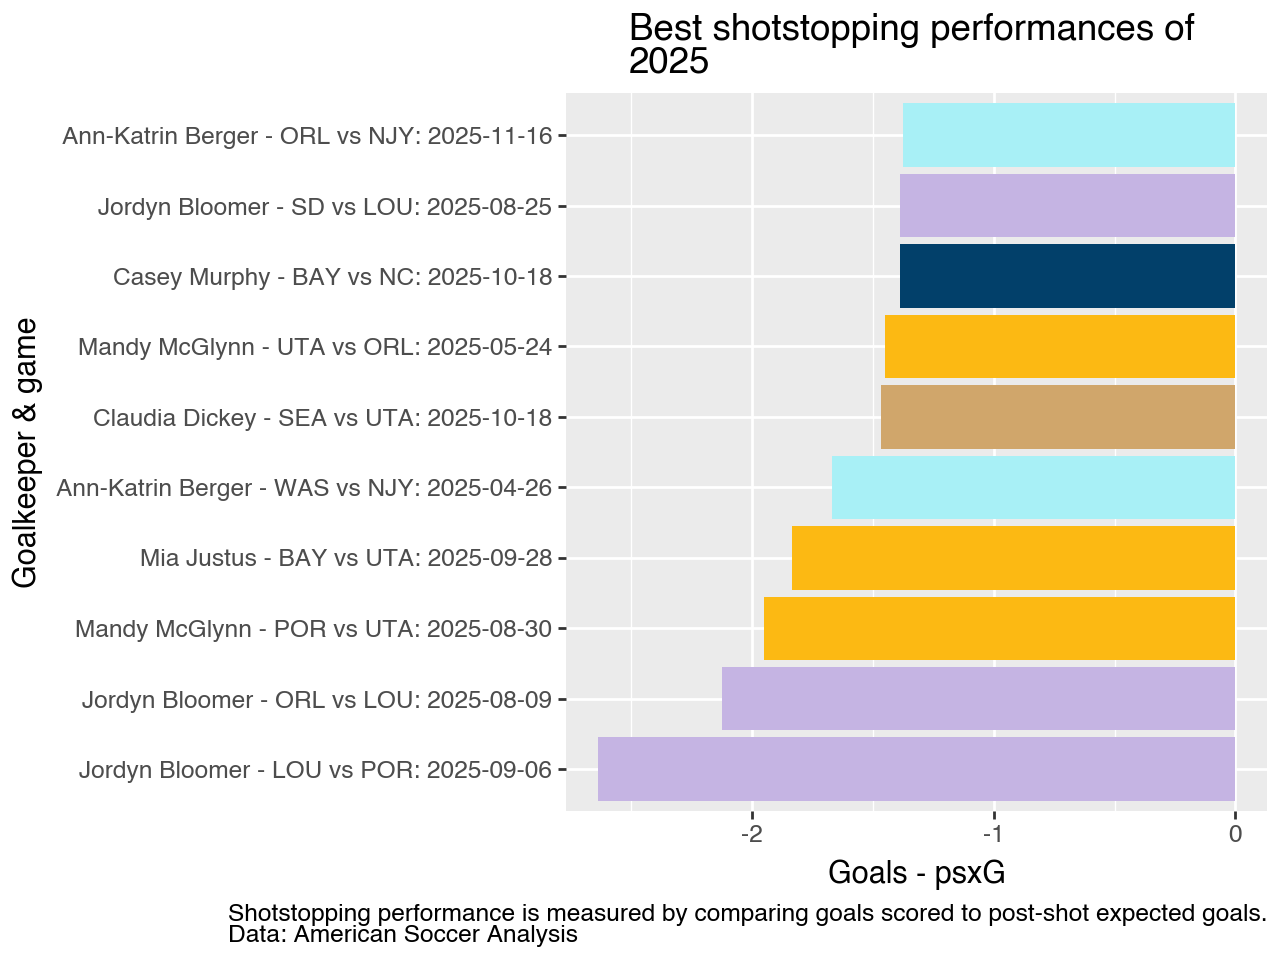

In [8]:
make_top_goalstop_plot(league_name="nwsl", season_name="2025", lim=10)

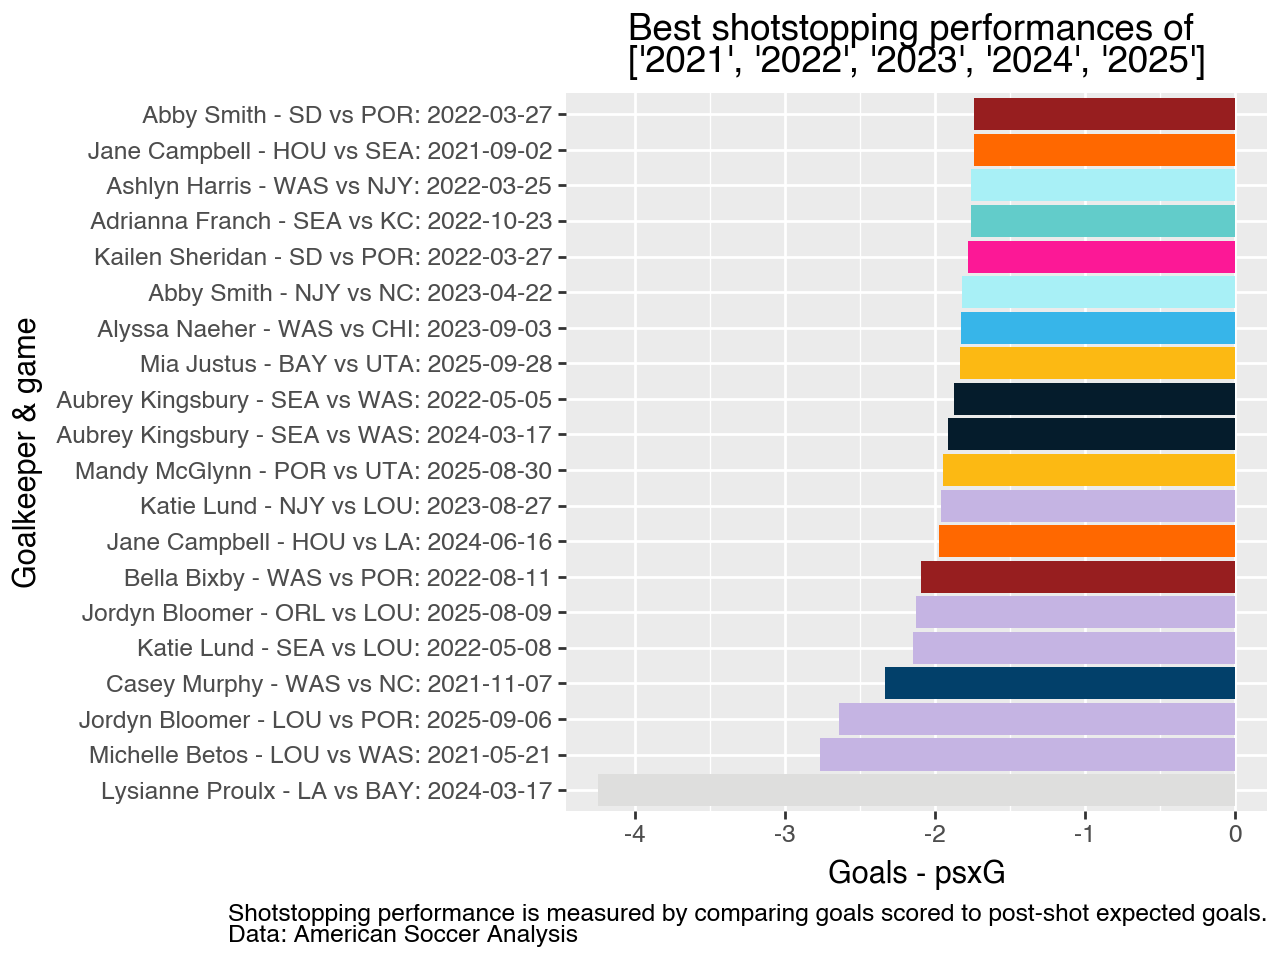

In [9]:
make_top_goalstop_plot(
    league_name="nwsl", season_name=["2021", "2022", "2023", "2024", "2025"], lim=20
)

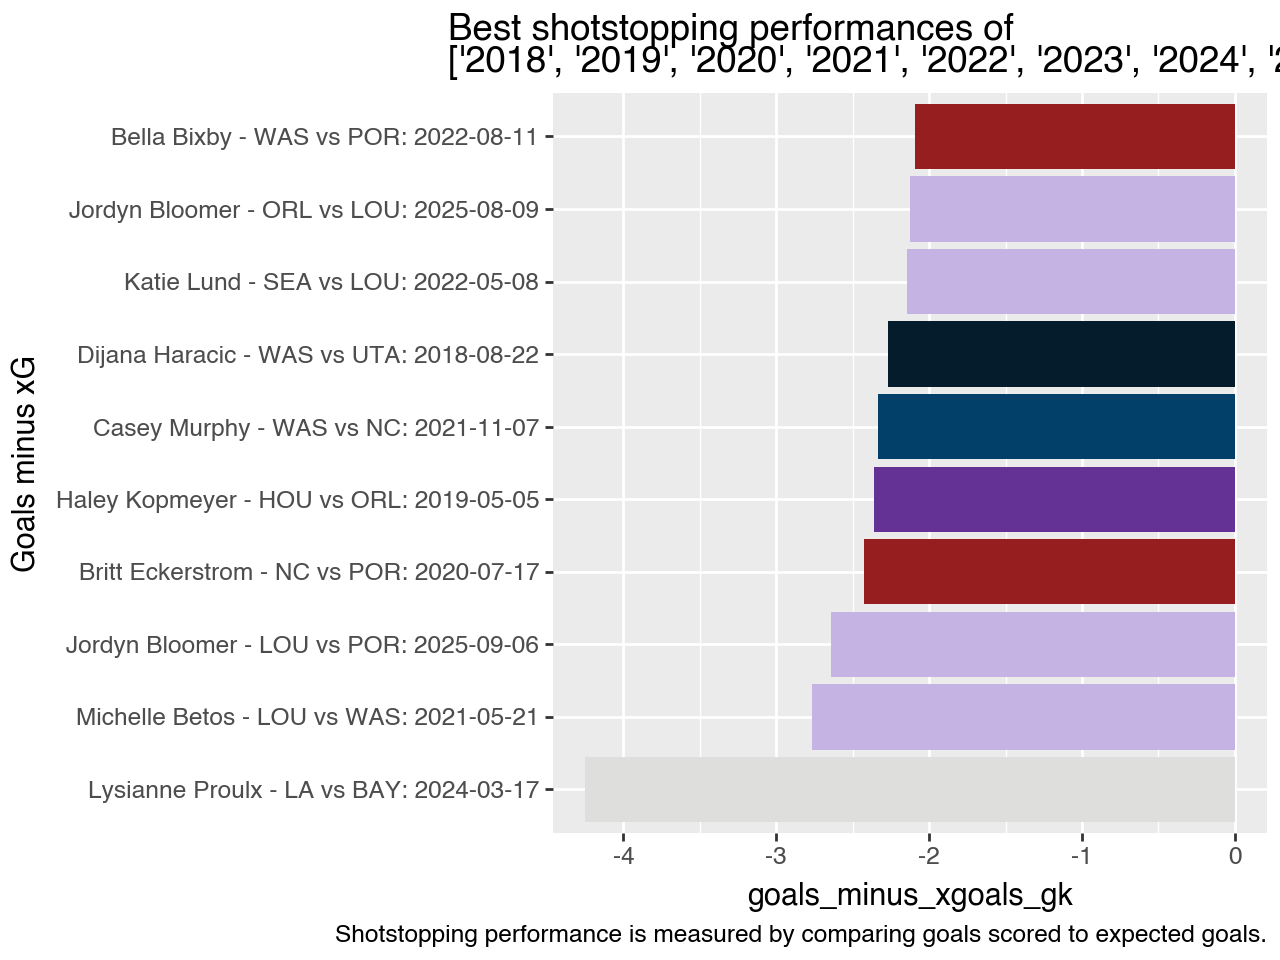

In [10]:
make_top_goalstop_plot(
    league_name="nwsl",
    season_name=[
        "2018",
        "2019",
        "2020",
        "2021",
        "2022",
        "2023",
        "2024",
        "2025",
    ],
)

In [11]:
games_df = asa_client.get_games(leagues="nwsl", seasons="2025")

In [12]:
games_df.game_id.to_list()

['jYQJmLzyqG',
 '2lqRpdk0Mr',
 'vzqoKN7kqa',
 'gOMnALRXQw',
 'gpMOpdaE5z',
 '0Oq6bZwAq6',
 '7VqGbYj65v',
 '0x5gjn2ZM7',
 'NWMWp4VK5l',
 'eVq3bDjD5W',
 'KAqBbO94qb',
 'Oa5wj2V8M1',
 'jYQJmLzPqG',
 'Xj5Ypd6AMb',
 'N6MmbPeZ5E',
 'e7Mzj2l6Mr',
 'ljqEmR2zqx',
 'p6qbjWOBq0',
 'XVqKzNWO50',
 'BLMvj2zOMx',
 'zeQZpd715K',
 '4wM4bDapqj',
 '4JMAb69k5K',
 'kRQajB2oMK',
 'xW5pbzrdQg',
 'KPqjj97Rq6',
 'aDQ0b2PP5E',
 'NPqxj2emM9',
 '9vQ2bD2aQK',
 'odMXpd8WMY',
 'KXMeZ6Or56',
 '9YqdjGkLMv',
 'Vj58bpY4Q8',
 'OlMljVr0qL',
 'a35rj2lA5L',
 '2vQ1bDLKMr',
 'eV5Dpo0A5K',
 '7vQ7bj32qD',
 'raMyj2ZO5d',
 'gjMNpdv0qK',
 'Pk5Lpd1O5O',
 'EGMPadlV5a',
 '315VpEe9Q9',
 '9z5kjkajMA',
 'wvq9b8pwQW',
 '2lqRpdR0Mr',
 'gOMnAL6XQw',
 'vzqoKNrkqa',
 'gpMOpdzE5z',
 '0Oq6bZlAq6',
 '7VqGbYm65v',
 '0x5gjnPZM7',
 'NWMWp4XK5l',
 'KAqBbOj4qb',
 'eVq3bDaD5W',
 'Oa5wj2Y8M1',
 'jYQJmL1PqG',
 'Xj5Ypd8AMb',
 'N6MmbP7Z5E',
 'e7Mzj296Mr',
 'ljqEmRjzqx',
 'p6qbjWeBq0',
 'XVqKzNYO50',
 'BLMvj2lOMx',
 '4wM4bD2pqj',
 'zeQZpdJ15K',
 '4JMAb6ak

In [13]:
shots_df = decorate_player_ids(
    decorate_team_ids(
        asa_client._get_stats(
            game_id=games_df.game_id.to_list(),
            type="shots",
            entity="games",
            leagues="nwsl",
        )
    )
)

In [14]:
shots_df.T

,0,1,2,3,4,5,6,7,8,9,...,3235,3236,3237,3238,3239,3240,3241,3242,3243,3244
game_id,gjMNpdn0qK,0Oq6bZ8dq6,Pk5LpdmO5O,7VqGbYm65v,2vQ1bDaKMr,XVqKzJ1K50,jYQJmL1PqG,9vQ2bDdaQK,gpMOpdOE5z,KXMeZ6er56,...,OlMljV70qL,Xj5Ypd8AMb,gOMnALrXQw,XVqKzJ1K50,eV5Dpo0A5K,0Oq6bZ8dq6,Xj5Ypd8AMb,ljqEmRjzqx,eV5Dpo0A5K,4JMAb69k5K
period_id,1,1,1,1,1,1,1,1,1,1,...,2,2,2,2,2,2,2,2,2,2
expanded_minute,1,1,1,1,1,1,1,1,2,2,...,103,104,98,96,102,103,105,97,104,104
game_minute,0,0,0,0,0,0,0,0,1,1,...,97,96,96,93,97,93,97,93,99,99
team_id,KPqjw8PQ6v,zeQZeazqKw,zeQZeazqKw,4wM4rZdqjB,aDQ0lzvQEv,KPqjw8PQ6v,KPqjw8PQ6v,XVqKeVKM01,4wM4rZdqjB,7vQ7BBzqD1,...,Pk5LeeNqOW,315VnJ759x,7VqG1lYMvW,4JMAk47qKg,315VnJ759x,zeQZeazqKw,Pk5LeeNqOW,7VqG1lYMvW,4JMAk47qKg,315VnJ759x
shooter_player_id,2lqRjRg2qr,vzqodvZjQa,vzqodvZjQa,odMX7LnxQY,xW5pr0w0Qg,9z5k7k7d5A,gpMOoKbnMz,BLMv7oZO5x,odMX8ElWMY,4JMAoyV2qK,...,gjMNPRApqK,0x5gLNAPq7,XVqKYmW0M0,p6qboZk4Q0,2vQ1R1WbMr,315VX01YQ9,BLMv78mR5x,7VqGj84Y5v,KAqBN78Xqb,2lqRlkRnMr
assist_player_id,0,2vQ143Ylqr,NWMWly9D5l,Xj5Y60lRqb,eVq3xWngQW,zeQZXkwD5K,vzqodLvBQa,0,gOMnR6AAMw,xW5prYLGQg,...,0,9z5k7ENJ5A,EGMPnKgxqa,2lqRRG6xqr,9YqdwJ8R5v,KXMekJVvq6,7VqGjYPj5v,N6MmepOxME,OlMlBWxRqL,0
shot_location_x,84.7,88.5,92.4,76.8,75.2,90.6,90.6,92.5,95.4,85.0,...,88.5,89.0,86.3,85.9,93.0,88.9,95.1,93.1,88.3,79.3
shot_location_y,46.4,64.1,45.8,45.6,36.8,50.5,66.2,32.4,56.7,40.1,...,50.0,61.7,73.7,63.0,50.7,35.0,47.3,53.7,48.9,32.1
shot_end_location_x,100.0,100.0,96.3,98.4,100.0,98.6,99.0,97.8,96.7,100.0,...,100.0,100.0,100.0,89.4,100.0,100.0,100.0,100.0,100.0,92.4


In [15]:
def explode_actions(action_list):
    row_dict = {}
    for action in action_list:
        action_type = action["action_type"]
        for action_value in [
            "goals_added_raw",
            # "goals_added_above_avg",
            # "count_actions",
        ]:
            row_dict[f"{action_type} {action_value}"] = action[action_value]

    return row_dict


gk_df = decorate_player_ids(
    decorate_team_ids(
        asa_client.get_goalkeeper_goals_added(
            leagues="nwsl",
            season=["2021", "2022", "2023", "2024", "2025"],
            split_by_games=True,
        )
    )
)

gk_df = pd.concat(
    [gk_df, pd.DataFrame(gk_df.data.apply(explode_actions).to_list())], axis=1
)

In [16]:
gk_df.sort_values("Shotstopping goals_added_raw", ascending=False)

,player_id,game_id,team_id,minutes_played,data,team,team_logo,player,player_headshot,Claiming goals_added_raw,Fielding goals_added_raw,Handling goals_added_raw,Passing goals_added_raw,Shotstopping goals_added_raw,Sweeping goals_added_raw
570,aDQ0NYeB5E,4wM480LzMj,315VnJ759x,101,"[{'action_type': 'Claiming', 'goals_added_raw'...",BAY,https://american-soccer-analysis-headshots.s3....,Lysianne Proulx,https://american-soccer-analysis-headshots.s3....,0.0088,0.0108,-0.1235,0.0360,4.2490,0.0530
1094,NWMWo0RzMl,KXMeZ6Or56,eV5DR6YQKn,107,"[{'action_type': 'Claiming', 'goals_added_raw'...",LOU,https://american-soccer-analysis-headshots.s3....,Jordyn Bloomer,https://american-soccer-analysis-headshots.s3....,0.0125,-0.0019,-0.0338,0.0554,2.8869,-0.0101
1245,NWMWVjJjQl,odMX9O6G5Y,eV5DR6YQKn,101,"[{'action_type': 'Claiming', 'goals_added_raw'...",LOU,https://american-soccer-analysis-headshots.s3....,Michelle Betos,https://american-soccer-analysis-headshots.s3....,-0.0224,0.0018,0.1650,0.0596,2.7652,0.0000
1085,NWMWo0RzMl,0Oq6bZwAq6,eV5DR6YQKn,100,"[{'action_type': 'Claiming', 'goals_added_raw'...",LOU,https://american-soccer-analysis-headshots.s3....,Jordyn Bloomer,https://american-soccer-analysis-headshots.s3....,-0.0007,0.0022,-0.1061,0.0612,2.6390,-0.0186
901,ljqE2r4oQx,gOMn93rxQw,zeQZeazqKw,130,"[{'action_type': 'Claiming', 'goals_added_raw'...",NC,https://american-soccer-analysis-headshots.s3....,Casey Murphy,https://american-soccer-analysis-headshots.s3....,-0.0246,0.0055,-0.0577,0.1328,2.3347,0.0133
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549,aDQ0aNglME,gOMn9vm8Qw,raMyrr25d2,96,"[{'action_type': 'Claiming', 'goals_added_raw'...",NJY,https://american-soccer-analysis-headshots.s3....,Ashlyn Harris,https://american-soccer-analysis-headshots.s3....,0.0044,0.0014,0.0532,0.0217,-2.8515,-0.0102
490,9z5k7P4g5A,jYQJ0ynD5G,KPqjw8PQ6v,101,"[{'action_type': 'Claiming', 'goals_added_raw'...",CHI,https://american-soccer-analysis-headshots.s3....,Alyssa Naeher,https://american-soccer-analysis-headshots.s3....,0.0000,-0.0022,-0.0179,0.0690,-3.0068,0.0984
664,eVq3ywVGMW,Pk5L0DRN5O,XVqKeVKM01,98,"[{'action_type': 'Claiming', 'goals_added_raw'...",ORL,https://american-soccer-analysis-headshots.s3....,Kaylie Collins,https://american-soccer-analysis-headshots.s3....,0.0069,0.0005,0.0000,0.0099,-3.0809,-0.0015
1011,N6MmodJvqE,jYQJmLDPqG,eV5DR6YQKn,105,"[{'action_type': 'Claiming', 'goals_added_raw'...",LOU,https://american-soccer-analysis-headshots.s3....,Katie Lund,https://american-soccer-analysis-headshots.s3....,0.0020,0.0034,0.0448,0.0670,-3.1347,0.0000


In [17]:
decorate_team_ids(asa_client.get_games(game_ids="4wM480LzMj")).T

,0
game_id,4wM480LzMj
date_time_utc,2024-03-17 23:30:00 UTC
home_score,0
away_score,1
home_team_id,kRQa8JOqKZ
away_team_id,315VnJ759x
referee_id,ljqEmaAqx0
stadium_id,7vQ7xbOMD1
home_manager_id,kRQa4w8qKZ
away_manager_id,NPqxLwgq9d
